# CPC353 - NATURAL LANGUAGE PROCESSING (ASSIGNMENT 2)


## LECTURER: Assoc. Prof. Dr. Tan Tien Ping 
### GROUP MEMBER:


| **NAME**                         | **MATRIX NUMBER** |
|----------------------------------|-------------------|
| NADIATUL FAKHIRA BINTI ZAKPAR    | 160307            |
| NORITA BINTI MUIN                | 160453            |




## Task4: Model Development
- Train a machine learning model to classify speaker changes. 
- Experiment with different window sizes or time-lagged parameters for better 
performance. 
- Evaluate performance using metrics such as F1-score, precision, and recall. 

In [7]:
import warnings
warnings.filterwarnings('ignore')

## Experiment 1 (IMBALANCED DATASET)
**frame_length/sliding window:** 20ms

**frame_shift/overlap:** 10ms 

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_10 (LSTM)              (None, 1, 64)             20224     
                                                                 
 dropout_10 (Dropout)        (None, 1, 64)             0         
                                                                 
 lstm_11 (LSTM)              (None, 32)                12416     
                                                                 
 dropout_11 (Dropout)        (None, 32)                0         
                                                                 
 dense_10 (Dense)            (None, 16)                528       
                                                                 
 dense_11 (Dense)            (None, 1)                 17        
                                                                 
Total params: 33,185
Trainable params: 33,185
Non-trai

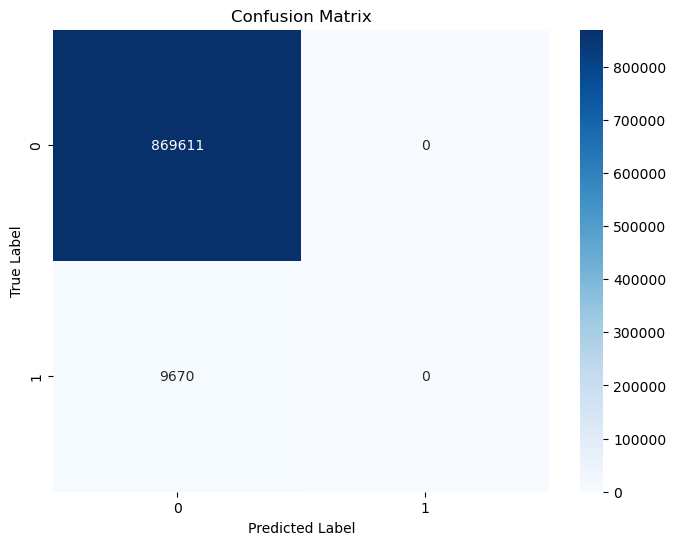

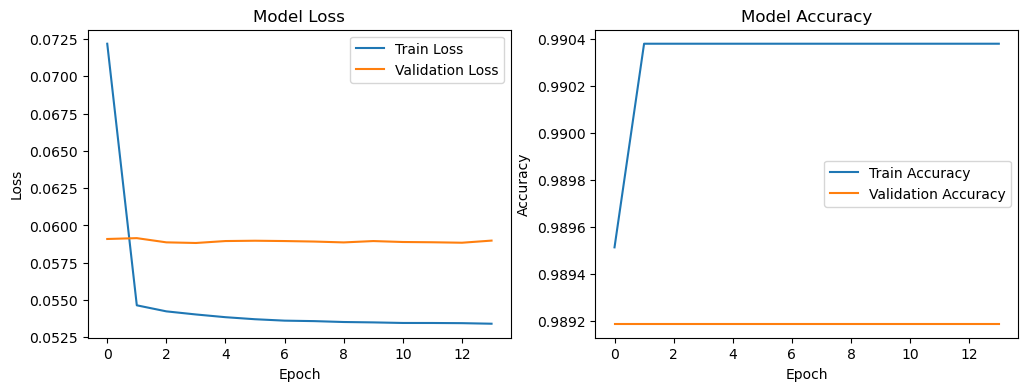

In [28]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def train_model(model, X_train, y_train, X_val, y_val):    
    # Callbacks for early stopping and model checkpointing
    early_stop = EarlyStopping(
        monitor='val_loss', 
        patience=10, 
        restore_best_weights=True
    )
    
    # Train the model with class weights
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=128,
        callbacks=[early_stop]
    )
    return history

def load_data(file_path):
    # Load data from CSV
    df = pd.read_csv(file_path)
    features = ['mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 
                'mfcc_6', 'mfcc_7', 'mfcc_8', 'mfcc_9', 'mfcc_10', 
                'mfcc_11', 'mfcc_12', 'mfcc_13', 'f0']
    X = df[features].values
    y = df['speaker_change'].values
    return X, y

def prepare_data(X, y):
    # Reshape for LSTM input
    X = X.reshape((X.shape[0], 1, X.shape[1]))
    return X, y

def create_lstm_model(input_shape):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=True),
        Dropout(0.3),
        LSTM(32),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def evaluate_model(model, X_test, y_test):
    # Predict and evaluate
    y_pred = (model.predict(X_test) > 0.5).astype(int)
    
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
    plt.tight_layout()
    plt.savefig('confusion_matrix.png')
    plt.close()

def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    
    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()
    
    plt.tight_layout()
    plt.savefig('training_history.png')
    plt.close()

def main():
    # Paths to your CSV files
    train_path = "C:/Users/Admin/SEM5/CPC353/assignment2/train_data1.csv"
    val_path = "C:/Users/Admin/SEM5/CPC353/assignment2/validation_data1.csv"
    test_path = "C:/Users/Admin/SEM5/CPC353/assignment2/test_data1.csv"
    
    # Load and prepare data
    X_train, y_train = load_data(train_path)
    X_val, y_val = load_data(val_path)
    X_test, y_test = load_data(test_path)

    X_train, y_train = prepare_data(X_train, y_train)
    X_val, y_val = prepare_data(X_val, y_val)
    X_test, y_test = prepare_data(X_test, y_test)
    
    # Create and train model
    model = create_lstm_model(input_shape=(1, 14))
    model.summary()
    history = train_model(model, X_train, y_train, X_val, y_val)
    
    # Evaluate and visualize
    evaluate_model(model, X_test, y_test)
    plot_training_history(history)


if __name__ == "__main__":
    main()


## Experiment 1 (HANDLE BALANCED DATASET)
**frame_length/sliding window:** 20ms

**frame_shift/overlap:** 10ms 

In [9]:
import pandas as pd
import numpy as np
from sklearn.utils import resample

def balance_dataset(df):
    # Separate majority and minority classes
    df_majority = df[df['speaker_change'] == 0]
    df_minority = df[df['speaker_change'] == 1]
    
    # Determine the number of samples
    n_samples = min(len(df_majority), len(df_minority))
    
    # Undersample the majority class
    df_majority_undersampled = resample(df_majority, 
                                         replace=False,    # sample without replacement
                                         n_samples=n_samples, 
                                         random_state=42)  # reproducible results
    
    # Undersample the minority class (if needed)
    df_minority_undersampled = resample(df_minority, 
                                         replace=False,    # sample without replacement
                                         n_samples=n_samples, 
                                         random_state=42)  # reproducible results
    
    # Combine the balanced datasets
    df_balanced = pd.concat([df_majority_undersampled, df_minority_undersampled])
    
    # Shuffle the balanced dataset
    df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
    
    return df_balanced


# Paths to your CSV files
train_path = "C:/Users/Admin/SEM5/CPC353/assignment2/train_data1.csv"
val_path = "C:/Users/Admin/SEM5/CPC353/assignment2/validation_data1.csv"
test_path = "C:/Users/Admin/SEM5/CPC353/assignment2/test_data1.csv"
    
# Load datasets
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

# Balance datasets
new_train_data = balance_dataset(train_df)
new_validation_data = balance_dataset(val_df)
new_test_data = balance_dataset(test_df)

# Save balanced datasets
new_train_data.to_csv('new_train_data1.csv', index=False)
new_validation_data.to_csv('new_validation_data1.csv', index=False)
new_test_data.to_csv('new_test_data1.csv', index=False)

# Verify class distribution
print("Training Data:")
print(new_train_data['speaker_change'].value_counts())
print("\nValidation Data:")
print(new_validation_data['speaker_change'].value_counts())
print("\nTest Data:")
print(new_test_data['speaker_change'].value_counts())

Training Data:
0    23591
1    23591
Name: speaker_change, dtype: int64

Validation Data:
1    9017
0    9017
Name: speaker_change, dtype: int64

Test Data:
1    9670
0    9670
Name: speaker_change, dtype: int64


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_2 (LSTM)               (None, 1, 64)             20224     
                                                                 
 dropout_2 (Dropout)         (None, 1, 64)             0         
                                                                 
 lstm_3 (LSTM)               (None, 32)                12416     
                                                                 
 dropout_3 (Dropout)         (None, 32)                0         
                                                                 
 dense_2 (Dense)             (None, 16)                528       
                                                                 
 dense_3 (Dense)             (None, 1)                 17        
                                                                 
Total params: 33,185
Trainable params: 33,185
Non-trai

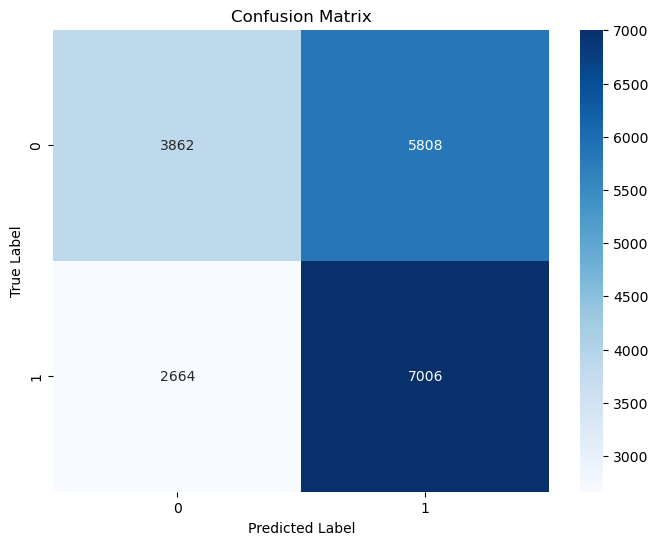

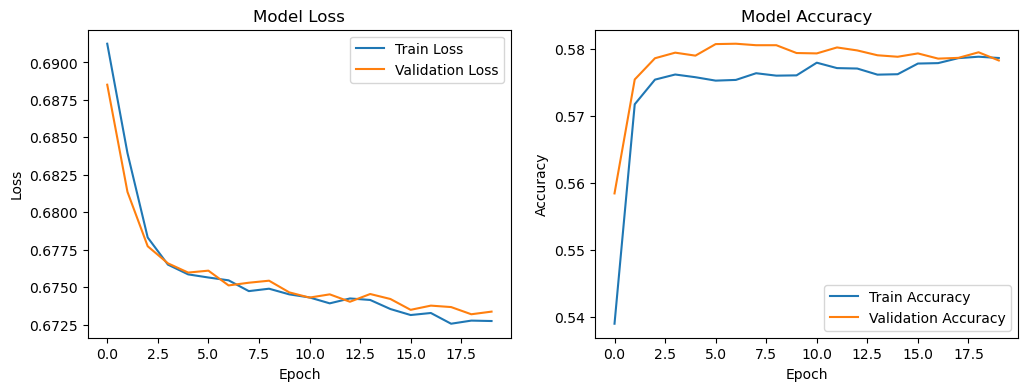

In [11]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

def calculate_class_weights(y):
    """Calculate class weights to handle class imbalance"""
    class_weights = compute_class_weight(
        class_weight='balanced', 
        classes=np.unique(y), 
        y=y
    )
    return dict(enumerate(class_weights))

def train_model(model, X_train, y_train, X_val, y_val):
    # Calculate class weights
    class_weights = calculate_class_weights(y_train)
    
    # Callbacks for early stopping and model checkpointing
    early_stop = EarlyStopping(
        monitor='val_loss', 
        patience=4, 
        restore_best_weights=True
    )
    
    # Train the model with class weights
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=64,
        class_weight=class_weights,  # Add class weights here
        callbacks=[early_stop]
    )
    return history

def load_data(file_path):
    # Load data from CSV
    df = pd.read_csv(file_path)
    features = ['mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 
                'mfcc_6', 'mfcc_7', 'mfcc_8', 'mfcc_9', 'mfcc_10', 
                'mfcc_11', 'mfcc_12', 'mfcc_13', 'f0']
    X = df[features].values
    y = df['speaker_change'].values
    return X, y

def prepare_data(X, y):
    # Reshape for LSTM input
    X = X.reshape((X.shape[0], 1, X.shape[1]))
    return X, y

def create_lstm_model(input_shape):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=True),
        Dropout(0.3),
        LSTM(32),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def evaluate_model(model, X_test, y_test):
    # Predict and evaluate
    y_pred = (model.predict(X_test) > 0.5).astype(int)
    
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
    plt.tight_layout()
    plt.savefig('confusion_matrix.png')
    plt.close()

def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    
    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()
    
    plt.tight_layout()
    plt.savefig('training_history.png')
    plt.close()

def main():
    # Paths to your CSV files
    train_path = "C:/Users/Admin/SEM5/CPC353/assignment2/new_train_data1.csv"
    val_path = "C:/Users/Admin/SEM5/CPC353/assignment2/new_validation_data1.csv"
    test_path = "C:/Users/Admin/SEM5/CPC353/assignment2/new_test_data1.csv"
    
    # Load and prepare data
    X_train, y_train = load_data(train_path)
    X_val, y_val = load_data(val_path)
    X_test, y_test = load_data(test_path)

    X_train, y_train = prepare_data(X_train, y_train)
    X_val, y_val = prepare_data(X_val, y_val)
    X_test, y_test = prepare_data(X_test, y_test)
    
    # Create and train model
    model = create_lstm_model(input_shape=(1, 14))
    model.summary()
    history = train_model(model, X_train, y_train, X_val, y_val)
    
    # Evaluate and visualize
    evaluate_model(model, X_test, y_test)
    plot_training_history(history)


if __name__ == "__main__":
    main()


## Experiment 2
**frame_length/sliding window:** 80ms

**frame_shift/overlap:** 10ms 

In [17]:
import pandas as pd
import numpy as np
from sklearn.utils import resample

def balance_dataset(df):
    # Separate majority and minority classes
    df_majority = df[df['speaker_change'] == 0]
    df_minority = df[df['speaker_change'] == 1]
    
    # Determine the number of samples
    n_samples = min(len(df_majority), len(df_minority))
    
    # Undersample the majority class
    df_majority_undersampled = resample(df_majority, 
                                         replace=False,    # sample without replacement
                                         n_samples=n_samples, 
                                         random_state=42)  # reproducible results
    
    # Undersample the minority class (if needed)
    df_minority_undersampled = resample(df_minority, 
                                         replace=False,    # sample without replacement
                                         n_samples=n_samples, 
                                         random_state=42)  # reproducible results
    
    # Combine the balanced datasets
    df_balanced = pd.concat([df_majority_undersampled, df_minority_undersampled])
    
    # Shuffle the balanced dataset
    df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
    
    return df_balanced


# Paths to your CSV files
train_path = "C:/Users/Admin/SEM5/CPC353/assignment2/train_data2.csv"
val_path = "C:/Users/Admin/SEM5/CPC353/assignment2/validation_data2.csv"
test_path = "C:/Users/Admin/SEM5/CPC353/assignment2/test_data2.csv"
    
# Load datasets
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

# Balance datasets
new_train_data = balance_dataset(train_df)
new_validation_data = balance_dataset(val_df)
new_test_data = balance_dataset(test_df)

# Save balanced datasets
new_train_data.to_csv('new_train_data2.csv', index=False)
new_validation_data.to_csv('new_validation_data2.csv', index=False)
new_test_data.to_csv('new_test_data2.csv', index=False)

# Verify class distribution
print("Training Data:")
print(new_train_data['speaker_change'].value_counts())
print("\nValidation Data:")
print(new_validation_data['speaker_change'].value_counts())
print("\nTest Data:")
print(new_test_data['speaker_change'].value_counts())

Training Data:
0    37726
1    37726
Name: speaker_change, dtype: int64

Validation Data:
0    14417
1    14417
Name: speaker_change, dtype: int64

Test Data:
1    15470
0    15470
Name: speaker_change, dtype: int64


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_4 (LSTM)               (None, 1, 64)             20224     
                                                                 
 dropout_4 (Dropout)         (None, 1, 64)             0         
                                                                 
 lstm_5 (LSTM)               (None, 32)                12416     
                                                                 
 dropout_5 (Dropout)         (None, 32)                0         
                                                                 
 dense_4 (Dense)             (None, 16)                528       
                                                                 
 dense_5 (Dense)             (None, 1)                 17        
                                                                 
Total params: 33,185
Trainable params: 33,185
Non-trai

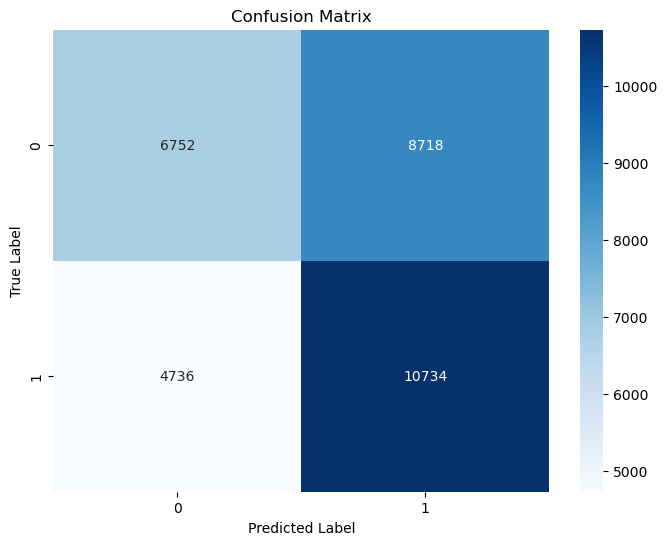

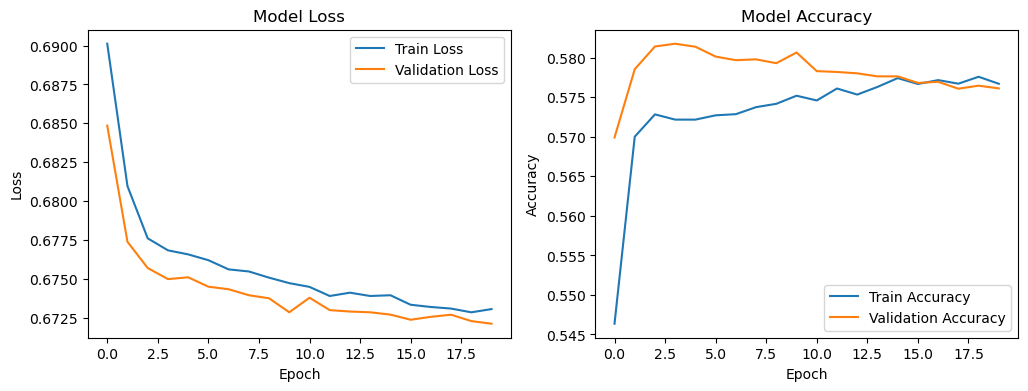

In [18]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

def calculate_class_weights(y):
    """Calculate class weights to handle class imbalance"""
    class_weights = compute_class_weight(
        class_weight='balanced', 
        classes=np.unique(y), 
        y=y
    )
    return dict(enumerate(class_weights))

def train_model(model, X_train, y_train, X_val, y_val):
    # Calculate class weights
    class_weights = calculate_class_weights(y_train)
    
    # Callbacks for early stopping and model checkpointing
    early_stop = EarlyStopping(
        monitor='val_loss', 
        patience=4, 
        restore_best_weights=True
    )
    
    # Train the model with class weights
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=64,
        class_weight=class_weights,  # Add class weights here
        callbacks=[early_stop]
    )
    return history

def load_data(file_path):
    # Load data from CSV
    df = pd.read_csv(file_path)
    features = ['mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 
                'mfcc_6', 'mfcc_7', 'mfcc_8', 'mfcc_9', 'mfcc_10', 
                'mfcc_11', 'mfcc_12', 'mfcc_13', 'f0']
    X = df[features].values
    y = df['speaker_change'].values
    return X, y

def prepare_data(X, y):
    # Reshape for LSTM input
    X = X.reshape((X.shape[0], 1, X.shape[1]))
    return X, y

def create_lstm_model(input_shape):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=True),
        Dropout(0.3),
        LSTM(32),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def evaluate_model(model, X_test, y_test):
    # Predict and evaluate
    y_pred = (model.predict(X_test) > 0.5).astype(int)
    
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
    plt.tight_layout()
    plt.savefig('confusion_matrix.png')
    plt.close()

def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    
    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()
    
    plt.tight_layout()
    plt.savefig('training_history.png')
    plt.close()

def main():
    # Paths to your CSV files
    train_path = "C:/Users/Admin/SEM5/CPC353/assignment2/new_train_data2.csv"
    val_path = "C:/Users/Admin/SEM5/CPC353/assignment2/new_validation_data2.csv"
    test_path = "C:/Users/Admin/SEM5/CPC353/assignment2/new_test_data2.csv"
    
    # Load and prepare data
    X_train, y_train = load_data(train_path)
    X_val, y_val = load_data(val_path)
    X_test, y_test = load_data(test_path)

    X_train, y_train = prepare_data(X_train, y_train)
    X_val, y_val = prepare_data(X_val, y_val)
    X_test, y_test = prepare_data(X_test, y_test)
    
    # Create and train model
    model = create_lstm_model(input_shape=(1, 14))
    model.summary()
    history = train_model(model, X_train, y_train, X_val, y_val)
    
    # Evaluate and visualize
    evaluate_model(model, X_test, y_test)
    plot_training_history(history)


if __name__ == "__main__":
    main()
